# Project #1 Part 3: Data Analysis $ Visualization
**Name:** Kyle Core
**Date:** 11/17/2026
This notebook contains the cleaned Fall 2024 entry-level computing majors survey dataset, and performs quantitative analysis and data visualization across four study questions. This is to help guide departmen recruiting strategies.

In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style for plots
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# Load the cleaned dataset
file_path = 'Majors Survey Results - Fall 2024 - Cleaned.csv'
df = pd.read_csv(file_path)

# Verify dataset shape
df.shape

(197, 89)

## Question 1: Student Demographics
Breakdown the demographics of students taking these entry-level courses, like age, race, ethnicity, and gender, to find which groups are underrepresented.

--- Gender Breakdown (%) ---


gender
Man                  82.233503
Woman                16.751269
Prefer not to say     1.015228
Name: proportion, dtype: float64


--- Age Breakdown (%) ---


age
18 and younger    40.609137
19-20             30.964467
21-24             13.197970
25-34             10.152284
35-64              4.568528
65+                0.507614
Name: proportion, dtype: float64

C:\Users\local_core.kyle\Temp\ipykernel_13960\528647489.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='gender', order=df['gender'].value_counts().index, palette='Blues_r', ax=ax[0])
C:\Users\local_core.kyle\Temp\ipykernel_13960\528647489.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='age', order=['18 and younger', '19-20', '21-24', '25-34', '35-64', '65+'], palette='viridis', ax=ax[1])


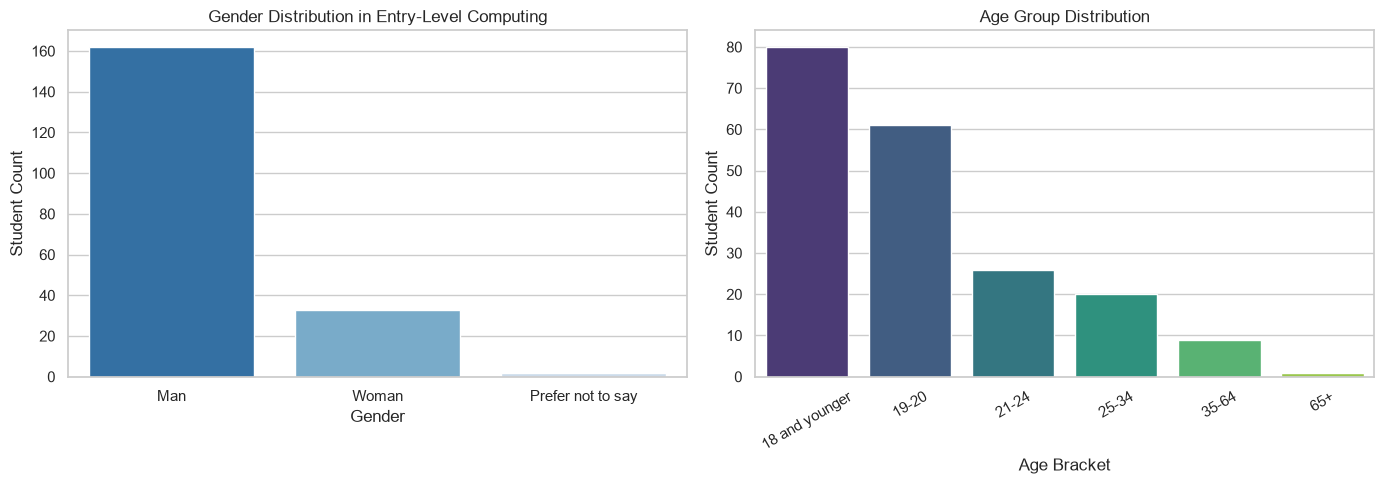

In [2]:
# Calculate percentage breakdowns for Gender, Age, and Race/Ethnicity
gender_pct = df['gender'].value_counts(normalize=True) * 100
age_pct = df['age'].value_counts(normalize=True) * 100

print("--- Gender Breakdown (%) ---")
display(gender_pct)

print("\n--- Age Breakdown (%) ---")
display(age_pct)

# Plot Gender Distribution
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=df, x='gender', order=df['gender'].value_counts().index, palette='Blues_r', ax=ax[0])
ax[0].set_title('Gender Distribution in Entry-Level Computing')
ax[0].set_xlabel('Gender')
ax[0].set_ylabel('Student Count')

# Plot Age Distribution
sns.countplot(data=df, x='age', order=['18 and younger', '19-20', '21-24', '25-34', '35-64', '65+'], palette='viridis', ax=ax[1])
ax[1].set_title('Age Group Distribution')
ax[1].set_xlabel('Age Bracket')
ax[1].set_ylabel('Student Count')
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

**Key Finding for Question 1:** Women only represent 16.75 percent of students in entry-level computing courses. Traditional college-age students (18-20) make up over 70% of enrollment.

## Question 2: Effective Information Sources for Underrepresented Groups
Which information sources were most effective at reaching underrepresented groups who enrolled in entry-level computing courses?

C:\Users\local_core.kyle\Temp\ipykernel_13960\2376573290.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=ur_sources_df.head(6), x='Adoption_Pct', y='Source', palette='crest')


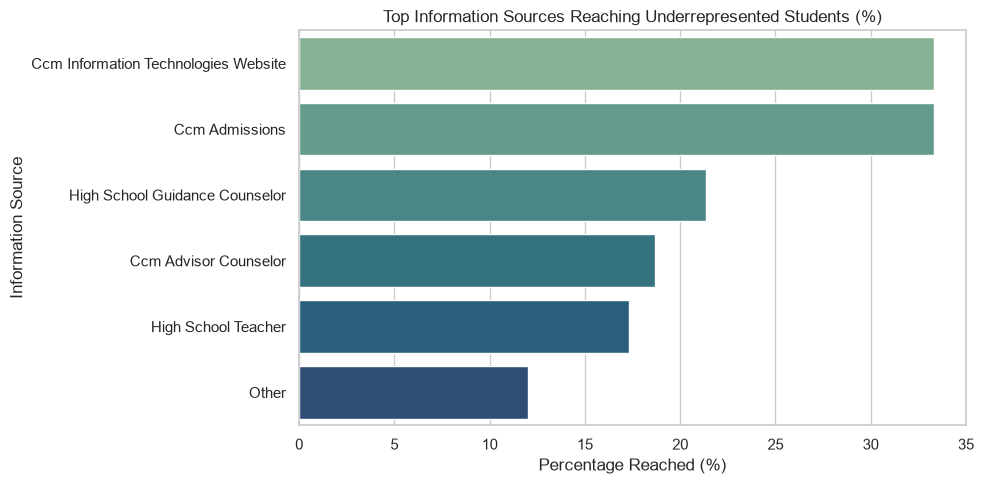

,Source,Adoption_Pct
2,Ccm Information Technologies Website,33.333333
3,Ccm Admissions,33.333333
0,High School Guidance Counselor,21.333333
4,Ccm Advisor Counselor,18.666667
1,High School Teacher,17.333333
8,Other,12.000000


In [3]:
# Identify underrepresented students (Woman or minority race/ethnicity)
def simplify_race(val):
    val_str = str(val)
    if 'White/Caucasian' in val_str and ';' not in val_str: return 'White/Caucasian'
    elif 'Hispanic or Latino' in val_str and ';' not in val_str: return 'Hispanic or Latino'
    elif 'Asian' in val_str and ';' not in val_str: return 'Asian'
    elif 'Black/African American' in val_str and ';' not in val_str: return 'Black/African American'
    else: return 'Multi-Racial / Other'

df['race_simplified'] = df['race_ethnicity'].apply(simplify_race)
df['underrepresented'] = (df['gender'] == 'Woman') | (df['race_simplified'].isin(['Hispanic or Latino', 'Black/African American']))

# Analyze information sources for underrepresented group
info_cols = [c for c in df.columns if 'did_you_receive_information_about_the_ccm_computing_programs' in c]

ur_sources = []
ur_total = df['underrepresented'].sum()

for col in info_cols:
    source_name = col.split('[')[-1].replace(']', '').replace('_', ' ').title()
    count = ((df[col] == 'Yes') & df['underrepresented']).sum()
    pct = (count / ur_total) * 100 if ur_total > 0 else 0
    ur_sources.append({'Source': source_name, 'Adoption_Pct': pct})

ur_sources_df = pd.DataFrame(ur_sources).sort_values(by='Adoption_Pct', ascending=False)

# Plot Top Information Sources
plt.figure(figsize=(10, 5))
sns.barplot(data=ur_sources_df.head(6), x='Adoption_Pct', y='Source', palette='crest')
plt.title('Top Information Sources Reaching Underrepresented Students (%)')
plt.xlabel('Percentage Reached (%)')
plt.ylabel('Information Source')
plt.tight_layout()
plt.show()

ur_sources_df.head(6)

**Key findings for Question 2:** The CCM Information Technologies Website and CCM Admissions tied as the most effective channels, each reaching 33.3% of underrepresented students. They were followed by High School Guidance Councelors at 21.3%.

## Question 3: CCM Outreach Activity Participation Rates
Which CCM outreach activities had the highest participation rates prior to college enrollment?

C:\Users\local_core.kyle\Temp\ipykernel_13960\3916401120.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=outreach_df.head(6), x='Participation_Pct', y='Activity', palette='mako')


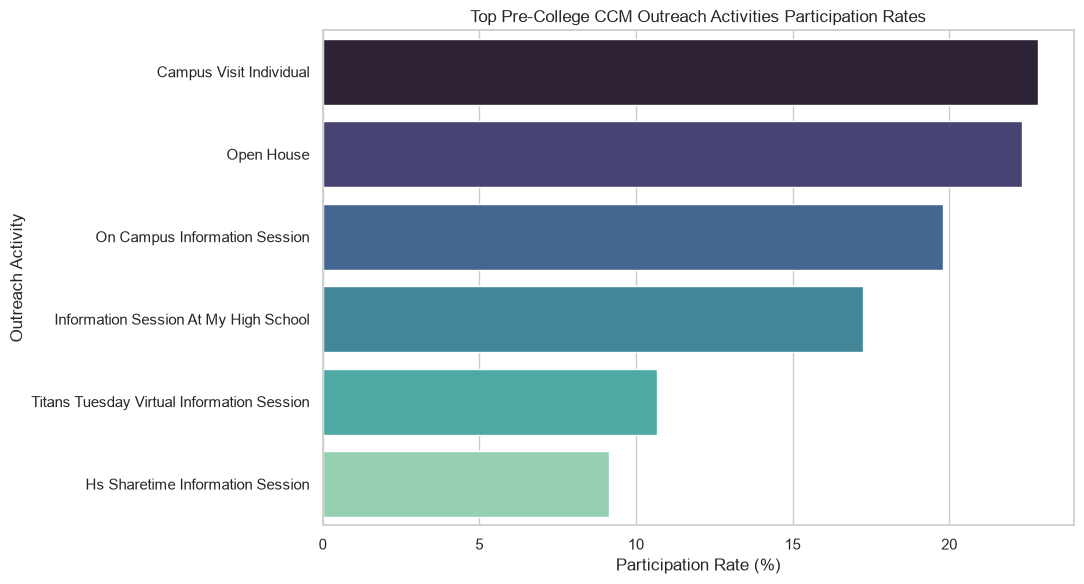

,Activity,Participation_Pct
11,Campus Visit Individual,22.842640
0,Open House,22.335025
2,On Campus Information Session,19.796954
9,Information Session At My High School,17.258883
3,Titans Tuesday Virtual Information Session,10.659898
6,Hs Sharetime Information Session,9.137056


In [4]:
# Analyze pre-college participation activities
outreach_cols = [c for c in df.columns if 'prior_to_applying' in c]

outreach_summary = []
total_students = len(df)

for col in outreach_cols:
    name = col.split('[')[-1].replace(']', '').replace('_', ' ').title()
    yes_count = (df[col] == 'Yes').sum()
    pct = (yes_count / total_students) * 100
    outreach_summary.append({'Activity': name, 'Participation_Pct': pct})

outreach_df = pd.DataFrame(outreach_summary).sort_values(by='Participation_Pct', ascending=False)

# Plot top outreach activities
plt.figure(figsize=(11, 6))
sns.barplot(data=outreach_df.head(6), x='Participation_Pct', y='Activity', palette='mako')
plt.title('Top Pre-College CCM Outreach Activities Participation Rates')
plt.xlabel('Participation Rate (%)')
plt.ylabel('Outreach Activity')
plt.tight_layout()
plt.show()

outreach_df.head(6)

**Key Finding for Question 3:** Individual Campus Visits (22.8%) and Open Houses (22.3) generated the highest participation rates for pre-college students. This shows us that on physical on-campus activites are the most important when it comes to bringing students to the school.

## Question 4: Top Motivations for Pursuing Computing
What were the top primary motivators for students pursuing computing majors at CCM?

C:\Users\local_core.kyle\Temp\ipykernel_13960\3193297262.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=motiv_df.head(6), x='Selection_Pct', y='Motivation', palette='rocket')


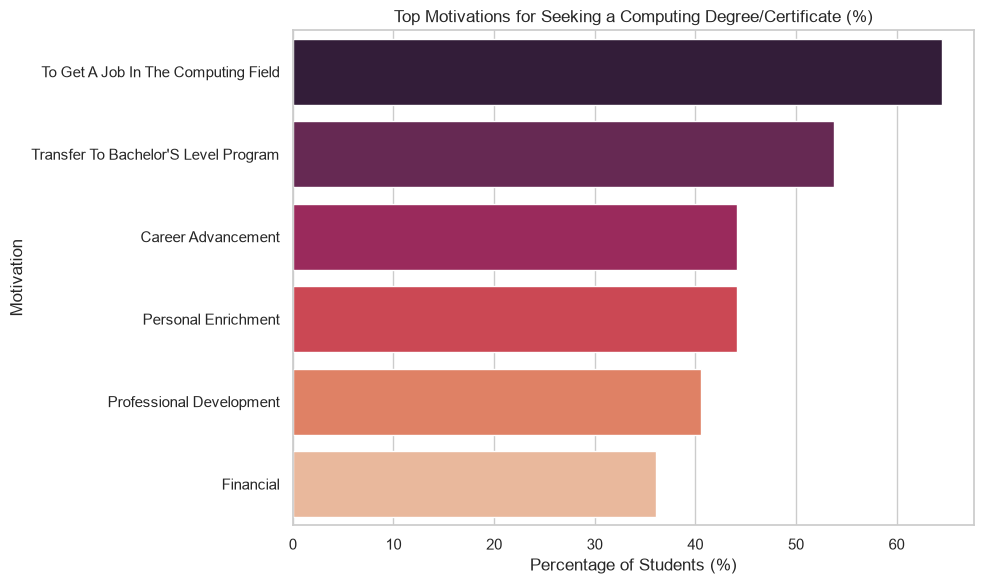

,Motivation,Selection_Pct
0,To Get A Job In The Computing Field,64.467005
1,Transfer To Bachelor'S Level Program,53.807107
3,Career Advancement,44.162437
11,Personal Enrichment,44.162437
5,Professional Development,40.609137
10,Financial,36.040609


In [6]:
# Analyze motivations for seeking a computing degree (counting only 'Yes' selections)
motiv_cols = [c for c in df.columns if 'what_motivated_you_to_seek_a_computing_degree' in c]
total_students = len(df)

motiv_summary = []
for col in motiv_cols:
    name = col.split('[')[-1].replace(']', '').replace('_', ' ').title()
    yes_count = (df[col] == 'Yes').sum()
    pct = (yes_count / total_students) * 100
    motiv_summary.append({'Motivation': name, 'Selection_Pct': pct})

motiv_df = pd.DataFrame(motiv_summary).sort_values(by='Selection_Pct', ascending=False)

# Plot top motivations
plt.figure(figsize=(10, 6))
sns.barplot(data=motiv_df.head(6), x='Selection_Pct', y='Motivation', palette='rocket')
plt.title('Top Motivations for Seeking a Computing Degree/Certificate (%)')
plt.xlabel('Percentage of Students (%)')
plt.ylabel('Motivation')
plt.tight_layout()
plt.show()

# Display the data table
motiv_df.head(6)

**Key finding for Question 4:** Securing a job in the computing field and transferring to a 4-year bachelor's program are the top primary motivators for student enrollment, which indicates that CCM's recruitment messaging shouldn focus on successfull career placement and easy transfer to 4-year colleges.